# Time Series Exercise -

### Follow along with the instructions in bold. Watch the solutions video if you get stuck!


## The Data

**Source: [https://datamarket.com/data/set/22ox/monthly-milk-production-pounds-per-cow-jan-62-dec-75#!ds=22ox&display=line](https://datamarket.com/data/set/22ox/monthly-milk-production-pounds-per-cow-jan-62-dec-75#!ds=22ox&display=line)**

Use the included .csv file for this exercise. (titled: monthly-milk-production.csv)

**Monthly milk production: pounds per cow. Jan 62 - Dec 75**


**Import numpy pandas and matplotlib**


In [1]:
import pandas as pd
import matplotlib as plt

**Use pandas to read the csv of the monthly-milk-production.csv file and set index_col='Month'**


In [2]:
milk = pd.read_csv('monthly-milk-production.csv', index_col='Month')

**Check out the head of the dataframe**


In [3]:
milk.head()

,Monthly milk production (pounds per cow)
Month,
1962-01,589
1962-02,561
1962-03,640
1962-04,656
1962-05,727


**Make the index a time series by using:**

```
milk.index = pd.to_datetime(milk.index)
```


In [4]:
milk.index = pd.to_datetime(milk.index)

**Plot out the time series data.**


<Axes: xlabel='Month'>

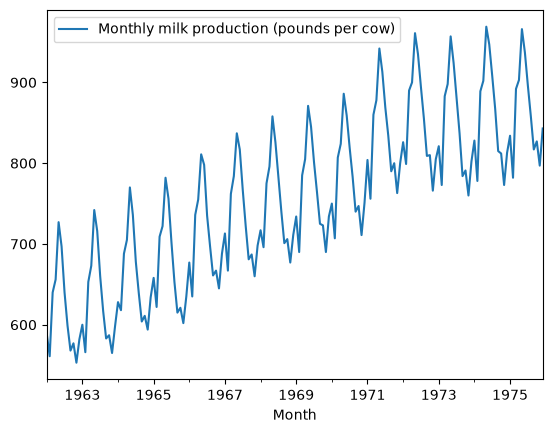

In [5]:
milk.plot()

---


### Train Test Split

**Let's attempt to predict a year's worth of data. (12 months or 12 steps into the future)**

**Create a test train split using indexing (hint: use .head() or tail() or .iloc[]). We don't want a random train test split, we want to specify that the test set is the last 12 months of data is the test set, with everything before it is the training.**


In [6]:
trainSet = milk.head(len(milk) - 12)

In [40]:
test_set = milk.tail(12)

### Scale the Data

**Use sklearn.preprocessing to scale the data using the MinMaxScaler. Remember to only fit_transform on the training data, then transform the test data. You shouldn't fit on the test data as well, otherwise you are assuming you would know about future behavior!**


In [41]:
from sklearn.preprocessing import MinMaxScaler

In [42]:
scaler = MinMaxScaler()

In [43]:
trainScaled = scaler.fit_transform(trainSet)

In [44]:
testScaled = scaler.transform(test_set)

## Batch Function

**We'll need a function that can feed batches of the training data. We'll need to do several things that are listed out as steps in the comments of the function. Remember to reference the previous batch method from the lecture for hints. Try to fill out the function template below, this is a pretty hard step, so feel free to reference the solutions!**


In [45]:
import numpy as np

def next_batch(training_data,batch_size,steps):
    """
    INPUT: Data, Batch Size, Time Steps per batch
    OUTPUT: A tuple of y time series results. y[:,:-1] and y[:,1:]
    """
    
    # STEP 1: Use np.random.randint to set a random starting point index for the batch.
    # Remember that each batch needs have the same number of steps in it.
    # This means you should limit the starting point to len(data)-steps
    randStart = np.random.randint(0, len(training_data) - steps)
    # STEP 2: Now that you have a starting index you'll need to index the data from
    # the random start to random start + steps + 1. Then reshape this data to be (1,steps+1)
    yBatch = np.array(training_data[randStart:randStart + steps + 1]).reshape(1, steps + 1)
    # STEP 3: Return the batches. You'll have two batches to return y[:,:-1] and y[:,1:]
    # You'll need to reshape these into tensors for the RNN to .reshape(-1,steps,1)
    return (
        yBatch[:, :-1].reshape(-1, steps, 1),
        yBatch[:, 1:].reshape(-1, steps, 1),
    )

## Setting Up The RNN Model


**Import TensorFlow**


In [46]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import tensorflow as tf

### The Constants

**Define the constants in a single cell. You'll need the following (in parenthesis are the values I used in my solution, but you can play with some of these):**

- Number of Inputs (1)
- Number of Time Steps (12)
- Number of Neurons per Layer (100)
- Number of Outputs (1)
- Learning Rate (0.03)
- Number of Iterations for Training (4000)
- Batch Size (1)


In [47]:
numOfInputs = 1
numOfTimeSteps = 12
numOfNeuronsPerLayer = 100
numOfOutputs = 1
learningRate = 0.03
numOfIterationsForTraining = 4000
batchSize = 1

**Create Placeholders for X and y. (You can change the variable names if you want). The shape for these placeholders should be [None,num_time_steps-1,num_inputs] and [None, num_time_steps-1, num_outputs] The reason we use num_time_steps-1 is because each of these will be one step shorter than the original time steps size, because we are training the RNN network to predict one point into the future based on the input sequence.**


In [48]:
tf.compat.v1.reset_default_graph()
tf.compat.v1.disable_eager_execution()

X = tf.compat.v1.placeholder(tf.float32, [None, numOfTimeSteps, numOfInputs])
y = tf.compat.v1.placeholder(tf.float32, [None, numOfTimeSteps, numOfOutputs])

**Now create the RNN Layer, you have complete freedom over this, use tf.contrib.rnn and choose anything you want, OutputProjectionWrappers, BasicRNNCells, BasicLSTMCells, MultiRNNCell, GRUCell etc... Keep in mind not every combination will work well! (If in doubt, the solutions used an Outputprojection Wrapper around a basic LSTM cell with relu activation.**


In [49]:
from tensorflow.python.ops.rnn_cell_impl import BasicLSTMCell

cell = BasicLSTMCell(
    num_units=numOfNeuronsPerLayer,
    activation=tf.nn.relu
)

/home/ayyytism/anaconda3/envs/tf-gpu5080/lib/python3.11/site-packages/tensorflow/python/keras/layers/legacy_rnn/rnn_cell_impl.py:709: UserWarning: `tf.nn.rnn_cell.BasicLSTMCell` is deprecated and will be removed in a future version. This class is equivalent as `tf.keras.layers.LSTMCell`, and will be replaced by that in Tensorflow 2.0.
  warnings.warn("`tf.nn.rnn_cell.BasicLSTMCell` is deprecated and will be "


**Now pass in the cells variable into tf.nn.dynamic_rnn, along with your first placeholder (X)**


In [50]:
outputs, states = tf.compat.v1.nn.dynamic_rnn(cell, X, dtype=tf.float32)

flat = tf.reshape(outputs, [-1, numOfNeuronsPerLayer])
w = tf.compat.v1.get_variable("w", [numOfNeuronsPerLayer, numOfOutputs])
b = tf.compat.v1.get_variable("b", [numOfOutputs])
outputs = tf.reshape(tf.matmul(flat, w) + b, [-1, numOfTimeSteps, numOfOutputs])

/home/ayyytism/anaconda3/envs/tf-gpu5080/lib/python3.11/site-packages/tensorflow/python/keras/engine/base_layer_v1.py:1702: UserWarning: `layer.add_variable` is deprecated and will be removed in a future version. Please use `layer.add_weight` method instead.
  warnings.warn('`layer.add_variable` is deprecated and '


### Loss Function and Optimizer

**Create a Mean Squared Error Loss Function and use it to minimize an AdamOptimizer, remember to pass in your learning rate.**


In [51]:
loss = tf.reduce_mean(tf.square(outputs - y))
optimizer = tf.compat.v1.train.AdamOptimizer(learning_rate=learningRate)
train = optimizer.minimize(loss)

**Initialize the global variables**


In [52]:
init = tf.compat.v1.global_variables_initializer()

**Create an instance of tf.train.Saver()**


In [53]:
saver = tf.compat.v1.train.Saver()

### Session

**Run a tf.Session that trains on the batches created by your next_batch function. Also add an a loss evaluation for every 100 training iterations. Remember to save your model after you are done training.**


In [54]:
with tf.compat.v1.Session() as sess:
    # CODE HERE!
    sess.run(init)
    for iteration in range(numOfIterationsForTraining):
        xBatch, yBatch = next_batch(trainScaled, batchSize, numOfTimeSteps)
        sess.run(train, feed_dict={X: xBatch, y: yBatch})
        if iteration % 100 == 0:
            mse = sess.run(loss, feed_dict={X: xBatch, y: yBatch})
            print(iteration, "\tMSE:", mse)
    # Save Model for Later
    saver.save(sess, "./ex_time_series_model")


W0000 00:00:1794050172.754050   13516 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1794050172.754666   13516 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13153 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5080, pci bus id: 0000:02:00.0, compute capability: 12.0a


0 	MSE: 1.9903532
100 	MSE: 0.014323112
200 	MSE: 0.014012206
300 	MSE: 0.008981928
400 	MSE: 0.010095385
500 	MSE: 0.011422068
600 	MSE: 0.009143667
700 	MSE: 0.012346598
800 	MSE: 0.008551255
900 	MSE: 0.009110296
1000 	MSE: 0.015850198
1100 	MSE: 0.011992698
1200 	MSE: 0.015546071
1300 	MSE: 0.012617155
1400 	MSE: 0.0077957637
1500 	MSE: 0.009721468
1600 	MSE: 0.013335471
1700 	MSE: 0.012007002
1800 	MSE: 0.010512394
1900 	MSE: 0.0092644105
2000 	MSE: 0.0108177615
2100 	MSE: 0.01096721
2200 	MSE: 0.011793758
2300 	MSE: 0.0055767163
2400 	MSE: 0.012303289
2500 	MSE: 0.012278748
2600 	MSE: 0.01284353
2700 	MSE: 0.0093766665
2800 	MSE: 0.01068272
2900 	MSE: 0.0077398256
3000 	MSE: 0.00948986
3100 	MSE: 0.012287319
3200 	MSE: 0.0064585754
3300 	MSE: 0.0121011445
3400 	MSE: 0.006106369
3500 	MSE: 0.009001757
3600 	MSE: 0.010527876
3700 	MSE: 0.0065769586
3800 	MSE: 0.0072626625
3900 	MSE: 0.01157762


---


## Predicting Future (Test Data)


**Show the test_set (the last 12 months of your original complete data set)**


In [55]:
# CODE HERE
test_set

,Monthly milk production (pounds per cow)
Month,
1975-01-01,834
1975-02-01,782
1975-03-01,892
1975-04-01,903
1975-05-01,966
1975-06-01,937
1975-07-01,896
1975-08-01,858
1975-09-01,817


**Now we want to attempt to predict these 12 months of data, using only the training data we had. To do this we will feed in a seed training_instance of the last 12 months of the training_set of data to predict 12 months into the future. Then we will be able to compare our generated 12 months to our actual true historical values from the test set!**


# Generative Session

### NOTE: Recall that our model is really only trained to predict 1 time step ahead, asking it to generate 12 steps is a big ask, and technically not what it was trained to do! Think of this more as generating new values based off some previous pattern, rather than trying to directly predict the future. You would need to go back to the original model and train the model to predict 12 time steps ahead to really get a higher accuracy on the test data. (Which has its limits due to the smaller size of our data set)

**Fill out the session code below to generate 12 months of data based off the last 12 months of data from the training set. The hardest part about this is adjusting the arrays with their shapes and sizes. Reference the lecture for hints.**


In [56]:
with tf.compat.v1.Session() as sess:
    
    # Use your Saver instance to restore your saved rnn time series model
    saver.restore(sess, "./ex_time_series_model")

    # CODE HERE!
    trainSeed = list(trainScaled[-numOfTimeSteps:].flatten())
    for iteration in range(12):
        xBatch = np.array(trainSeed[-numOfTimeSteps:]).reshape(1, numOfTimeSteps, 1)
        yPred = sess.run(outputs, feed_dict={X: xBatch})
        trainSeed.append(yPred[0, -1, 0])

INFO:tensorflow:Restoring parameters from ./ex_time_series_model


W0000 00:00:1794050389.008448   13516 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1794050389.009147   13516 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13153 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5080, pci bus id: 0000:02:00.0, compute capability: 12.0a


**Show the result of the predictions.**


In [57]:
trainSeed

[np.float64(0.6610576923076923),
 np.float64(0.5408653846153846),
 np.float64(0.8076923076923077),
 np.float64(0.8389423076923077),
 np.float64(1.0000000000000002),
 np.float64(0.9471153846153848),
 np.float64(0.8533653846153848),
 np.float64(0.7548076923076923),
 np.float64(0.6298076923076923),
 np.float64(0.622596153846154),
 np.float64(0.528846153846154),
 np.float64(0.625),
 np.float32(0.673193),
 np.float32(0.73096275),
 np.float32(0.78657866),
 np.float32(0.82208085),
 np.float32(0.7933564),
 np.float32(0.74948025),
 np.float32(0.7464051),
 np.float32(0.7166457),
 np.float32(0.8065014),
 np.float32(0.83162475),
 np.float32(0.80381775),
 np.float32(0.832592)]

**Grab the portion of the results that are the generated values and apply inverse_transform on them to turn them back into milk production value units (lbs per cow). Also reshape the results to be (12,1) so we can easily add them to the test_set dataframe.**


In [58]:
results = scaler.inverse_transform(np.array(trainSeed[-12:]).reshape(12, 1))

**Create a new column on the test_set called "Generated" and set it equal to the generated results. You may get a warning about this, feel free to ignore it.**


In [59]:
test_set["Generated"] = results

**View the test_set dataframe.**


In [ ]:
test_set

,Milk Production,Generated
Month,,
1975-01-01 01:00:00,834.0,825.486877
1975-02-01 01:00:00,782.0,806.589233
1975-03-01 01:00:00,892.0,894.516663
1975-04-01 01:00:00,903.0,898.137207
1975-05-01 01:00:00,966.0,959.006165
1975-06-01 01:00:00,937.0,933.891113
1975-07-01 01:00:00,896.0,908.463257
1975-08-01 01:00:00,858.0,879.789612
1975-09-01 01:00:00,817.0,841.445801


**Plot out the two columns for comparison.**


<Axes: xlabel='Month'>

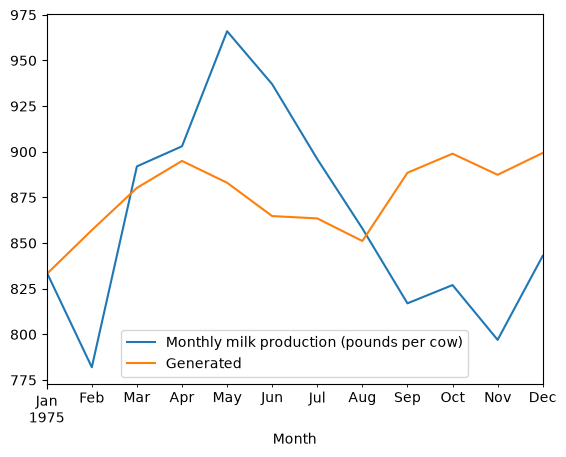

In [60]:
test_set.plot()

# Great Job!

Play around with the parameters and RNN layers, does a faster learning rate with more steps improve the model? What about GRU or BasicRNN units? What if you train the original model to not just predict one timestep ahead into the future, but 3 instead? Lots of stuff to add on here!
